# 2. Modélisation et scoring

**Objectif** : construire un modèle prédisant la probabilité de réponse positive à la 
campagne, comparer deux approches (régression logistique, Random Forest), et transformer 
les probabilités prédites en classes de score exploitables commercialement.

## Rechargement et préparation des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

possible_paths = [
    Path("data/mailing_fin.txt"),
    Path("../data/mailing_fin.txt"),
    Path("mailing_fin.txt")
]
data_path = None
for path in possible_paths:
    if path.exists():
        data_path = path
        break
if data_path is None:
    raise FileNotFoundError("Le fichier mailing_fin.txt est introuvable.")

df = pd.read_csv(data_path, sep="\t")

# On réapplique les traitements faits dans 01_EDA_et_tests_statistiques.ipynb
df = df.dropna(subset=["SEX"])

bins = [18, 25, 35, 45, 55, 65, 75]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65", "66-75"]
df["AGE_CAT"] = pd.cut(df["AGE"], bins=bins, labels=labels, include_lowest=True)

## 12. Préparation des données pour la modélisation

On transforme la variable cible en variable binaire : `NON` = 0, `OUI` = 1.

In [2]:
df["RETOUR_BIN"] = df["RETOUR"].map({"NON": 0, "OUI": 1})
df[["RETOUR", "RETOUR_BIN"]].head()

,RETOUR,RETOUR_BIN
0,NON,0
2,OUI,1
4,NON,0
5,NON,0
7,NON,0


In [3]:
# Variables explicatives retenues (INCOME exclue car non significative, cf. 01_EDA)
features = [
    "AGE_CAT", "SEX", "MARRIED", "OWNHOME", "LOC", "COA6",
    "FICO", "BUY6", "BUY12", "BUY18", "VALUE24"
]

X = df[features]
y = df["RETOUR_BIN"]

# One-Hot Encoding des variables qualitatives (drop_first=True évite la redondance)
X = pd.get_dummies(X, drop_first=True)
X.head()

,MARRIED,OWNHOME,COA6,FICO,BUY6,BUY12,BUY18,VALUE24,AGE_CAT_26-35,AGE_CAT_36-45,...,AGE_CAT_56-65,AGE_CAT_66-75,SEX_M,LOC_B,LOC_C,LOC_D,LOC_E,LOC_F,LOC_G,LOC_H
0,1,0,0,748,0,0,0,209,False,True,...,False,False,False,False,False,False,False,False,False,False
2,0,0,0,727,0,0,1,447,False,False,...,False,False,False,False,False,False,False,False,False,False
4,0,1,0,646,0,0,0,233,False,False,...,True,False,False,False,False,False,False,False,False,False
5,1,0,0,685,0,0,0,100,False,False,...,True,False,False,False,False,False,False,False,False,False
7,1,0,0,758,1,1,1,507,False,False,...,False,False,True,False,False,False,False,False,False,False


## 13. Découpage en base d'apprentissage et base de test

70 % pour l'entraînement, 30 % pour le test. `stratify=y` conserve la même proportion 
de répondants/non-répondants dans les deux échantillons.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

X_train : (27804, 21)
X_test : (11917, 21)


## 14. Standardisation des variables quantitatives

La standardisation met les variables quantitatives sur une échelle comparable, 
ce qui facilite l'estimation de la régression logistique.

In [5]:
from sklearn.preprocessing import StandardScaler

num_vars_model = ["FICO", "BUY6", "BUY12", "BUY18", "VALUE24"]

# On force le type float avant standardisation : nécessaire car ces colonnes sont
# actuellement en int64, et pandas refuse désormais d'y insérer des valeurs décimales
X_train[num_vars_model] = X_train[num_vars_model].astype(float)
X_test[num_vars_model] = X_test[num_vars_model].astype(float)

scaler = StandardScaler()

# fit sur le train uniquement, transform sur le train et le test (évite la fuite de données)
X_train.loc[:, num_vars_model] = scaler.fit_transform(X_train[num_vars_model])
X_test.loc[:, num_vars_model] = scaler.transform(X_test[num_vars_model])

## 15. Modèle 1 — Régression logistique

La variable cible étant déséquilibrée, `class_weight="balanced"` donne plus de poids 
à la classe minoritaire (`OUI`) pendant l'entraînement.

In [6]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

## 16. Évaluation de la régression logistique

L'accuracy seule n'est pas suffisante ici puisque la cible est déséquilibrée : 
on utilise la matrice de confusion, le rapport de classification et l'AUC.

In [7]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("AUC :", roc_auc_score(y_test, y_proba))

[[6593 3705]
 [ 711  908]]
              precision    recall  f1-score   support

           0       0.90      0.64      0.75     10298
           1       0.20      0.56      0.29      1619

    accuracy                           0.63     11917
   macro avg       0.55      0.60      0.52     11917
weighted avg       0.81      0.63      0.69     11917

AUC : 0.6553274495392463


**Observation** : le modèle présente une AUC d'environ 0,655, ce qui indique une 
capacité de discrimination modérée. Le rappel de la classe positive est d'environ 0,56 : 
le modèle identifie environ 56 % des clients ayant effectivement répondu positivement. 
La précision de la classe positive reste plus faible — une partie importante des clients 
ciblés ne répondent pas réellement. Dans un contexte de scoring marketing, l'objectif 
n'est pas de prédire parfaitement la classe, mais surtout de **hiérarchiser** les clients 
selon leur probabilité de réponse.

## 17. Modèle 2 — Random Forest (comparaison)

On teste un second modèle pour vérifier si une approche non-linéaire capture mieux 
la relation entre les variables et la réponse au mailing.

In [8]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=8,
    class_weight="balanced", random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
print("AUC Random Forest :", roc_auc_score(y_test, y_proba_rf))

[[7336 2962]
 [ 856  763]]
              precision    recall  f1-score   support

           0       0.90      0.71      0.79     10298
           1       0.20      0.47      0.29      1619

    accuracy                           0.68     11917
   macro avg       0.55      0.59      0.54     11917
weighted avg       0.80      0.68      0.72     11917

AUC Random Forest : 0.6558791377062367


**Résultat comparatif :**

| Modèle | AUC |
|---|---|
| Régression logistique | 0.655 |
| Random Forest | 0.656 |

Les deux modèles obtiennent une performance quasi identique. Le Random Forest, capable de 
détecter des relations non-linéaires et des interactions entre variables, n'apporte ici 
aucun gain significatif — ce qui suggère que la relation entre les variables explicatives 
et la probabilité de réponse est largement **linéaire**. Ce résultat plaide en faveur du 
modèle le plus simple (régression logistique) pour la mise en production : à performance 
égale, il est plus rapide, plus stable et surtout plus interprétable (chaque coefficient 
s'interprète directement en termes d'effet sur la probabilité de réponse).

## 18. Courbe ROC (régression logistique)

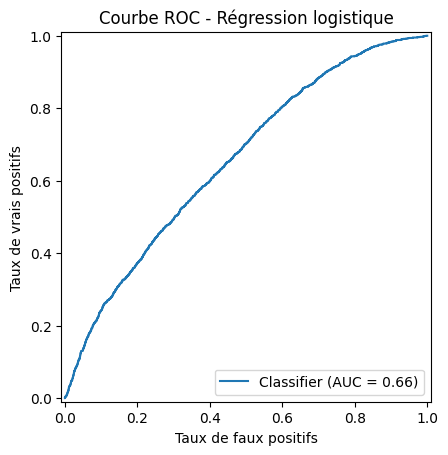

In [9]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("Courbe ROC - Régression logistique")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.show()

**Observation** : la courbe ROC confirme une AUC d'environ 0,66. Le modèle fait 
mieux qu'un tirage aléatoire, mais ses performances restent modérées. Il reste néanmoins 
utile pour hiérarchiser les clients dans une logique de ciblage commercial.

## 19. Construction des classes de score

On transforme les probabilités prédites par la régression logistique en cinq classes 
de score, de `Très faible` à `Très élevé`, pour un usage opérationnel en marketing.

In [10]:
df_score = X_test.copy()
df_score["RETOUR_REEL"] = y_test
df_score["PROBA_RETOUR"] = y_proba

df_score["CLASSE_SCORE"] = pd.qcut(
    df_score["PROBA_RETOUR"],
    q=5,
    labels=["Très faible", "Faible", "Moyen", "Élevé", "Très élevé"]
)

df_score.groupby("CLASSE_SCORE")["RETOUR_REEL"].mean() * 100

CLASSE_SCORE
Très faible     4.488255
Faible         10.574906
Moyen          13.764163
Élevé          15.862358
Très élevé     23.238255
Name: RETOUR_REEL, dtype: float64

**Observation** : l'analyse des classes de score montre une progression nette du 
taux de retour positif selon le niveau de score. Les clients de la classe `Très faible` 
présentent un taux de retour d'environ 4,5 %, contre environ 23,2 % pour la classe 
`Très élevé`. Cette progression confirme que le modèle permet de classer les clients 
selon leur appétence à l'offre marketing.

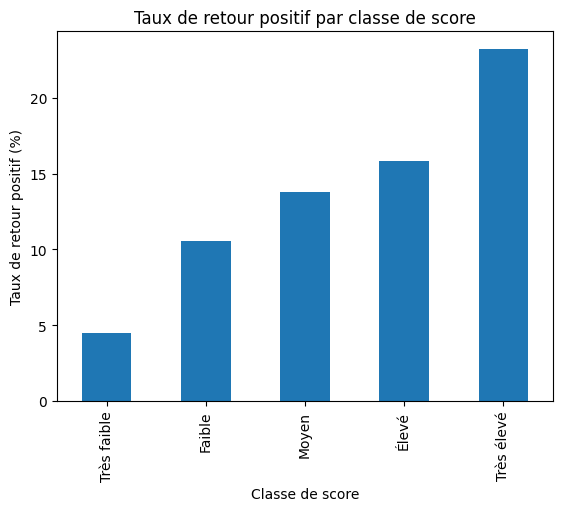

In [11]:
analyse_score = df_score.groupby("CLASSE_SCORE")["RETOUR_REEL"].mean() * 100

analyse_score.plot(kind="bar")
plt.title("Taux de retour positif par classe de score")
plt.xlabel("Classe de score")
plt.ylabel("Taux de retour positif (%)")
plt.show()

## 20. Conclusion générale

L'objectif de ce projet était de construire un modèle de scoring marketing permettant 
d'identifier les clients les plus susceptibles de répondre positivement à une offre 
commerciale.

L'analyse exploratoire a montré que la variable cible `RETOUR` est déséquilibrée 
(~86,4 % de non-répondants contre ~13,6 % de répondants). Les tests statistiques 
(Khi-deux, Student) ont permis d'identifier plusieurs variables discriminantes : classe 
d'âge, localité, statut de propriété, nombre de commandes passées et montant des 
commandes sur les 24 derniers mois.

Deux modèles ont été comparés : une régression logistique et un Random Forest, obtenant 
des performances quasi identiques (AUC ≈ 0,655-0,656). Ce résultat suggère que la relation 
entre les variables et la probabilité de réponse est largement linéaire, et plaide pour 
la régression logistique en production, à la fois plus simple et plus interprétable.

La création de classes de score confirme l'utilité opérationnelle du modèle : le taux de 
retour positif passe d'environ 4,5 % pour la classe `Très faible` à environ 23,2 % pour la 
classe `Très élevé`, permettant de prioriser les actions commerciales futures vers les 
clients les plus susceptibles de répondre.